<a href="https://colab.research.google.com/github/MalenaLesc/DataSet/blob/main/TP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Trabajo Practico - Explotación de la información**

---
##Objetivo del analisis y Dataset elegido:

El Dataset elegido fue el que se encuentra en el siguienre link, proveniente de una fuente gubernamental del país: https://datos.produccion.gob.ar/dataset/graduados-universitarios-del-sistema-araucano-2016-2018

La información que contiene este set de datos, a grandes rasgos, es orientada a la situacion laboral de estudiantes graduados entre los años 2016 y 2018.

Para este trabajo me interesa analizar el nivel de inserción laboral de los graduados universitarios y si existen diferencias según el área de estudio, género, región, tipo de institución y año de egreso. Estudiar qué características se relacionan con el acceso a un empleo registrado y con el nivel de remuneración e identificar patrones que permitan determinar qué áreas de formación presentan mejores resultados laborales.


#1. Importamos las librerias a utilizar y el Dataset

In [141]:
#importamos las librerias de datos fundamentales, NumPy y Pandas
import pandas as pd
import numpy as np

#agregamos la libreria Matplotlib
import matplotlib.pyplot as plt



In [142]:
# Dataset principal comprimido
url_csv = "https://github.com/MalenaLesc/DataSet/raw/refs/heads/main/base_araucano.zip"

df = pd.read_csv(url_csv, compression="zip")


#2. Informacion sobre el Dataset

Como se puede observar a continuacion, este Dataset cuenta con 820335 filas y 13 columnas, en las columnas se puede observar que no se encuentra el dato directamente sino que almacenan un ID con el cual se debe consultar su verdadero valor en otro archivo llamado "diccionario".

####Columnas:

`id`: Identificador único o clave de registro de cada egresado universitario en el sistema.

`salario`: Remuneración o salario registrado del graduado (contiene un ~41.6% de valores nulos, posiblemente correspondientes a graduados sin un empleo registrado en ese período).

`anio`: El año en el cual se realiza el relevamiento o consulta de la situación laboral.

`anioegreso`: El año en el que la persona se graduó o egresó de su carrera universitaria.

`anionac`: El año de nacimiento del graduado (útil para calcular la edad al egresar o al momento del relevamiento).

`rama`: Gran área temática o macro-disciplina de la carrera cursada (por ejemplo, Ciencias Sociales, Ciencias Aplicadas, Ciencias de la Salud, etc.).

`disciplina`: El campo de estudio específico o carrera del graduado (por ejemplo, Economía y Administración, Ingeniería, etc.).

`tipo_titulo`: El nivel académico del título obtenido (por ejemplo, Pregrado, Tecnicatura, Grado y profesorado, o Posgrado).

`gestion`: El tipo de administración de la institución universitaria donde se graduó (Estatal o Privada).

`genero`: Género del graduado (por ejemplo, mujer o varon).

`region`: La región geográfica del país donde se localiza la institución o se registra la actividad laboral (por ejemplo, CABA, Buenos Aires, Patagonia, etc.).

`tamaño`: El tamaño de la empresa u organización empleadora del graduado, categorizado por el número de empleados (por ejemplo, pequeña, mediana, grande).

`letra`: La descripción del sector de actividad económica del empleador según el clasificador oficial (por ejemplo, Salud humana, Enseñanza, Servicios inmobiliarios).

`letra.1`: El código alfabético estandarizado (una sola letra) que representa formalmente al sector de actividad de la columna anterior (por ejemplo, Q, N, O).

In [143]:
df

,id,rama_id,disciplina_id,tipo_titulo_id,gestion_id,genero_id,region_id,tamaño_id,letra_id,salario,anio,anioegreso,anionac
0,1,1,1,4,1,1,1,NaN,NaN,NaN,2019,2017,1976.0
1,1,1,1,4,1,1,1,NaN,NaN,NaN,2020,2017,1976.0
2,1,1,1,4,1,1,1,NaN,NaN,NaN,2021,2017,1976.0
3,2,1,1,4,1,1,2,NaN,NaN,NaN,2019,2018,1980.0
4,2,1,1,4,1,1,2,NaN,NaN,NaN,2020,2018,1980.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
820330,273444,1,1,3,2,2,1,2.0,19.0,62557.969,2020,2018,1998.0
820331,273444,1,1,3,2,2,1,NaN,NaN,NaN,2021,2018,1998.0
820332,273445,3,18,2,2,1,1,NaN,NaN,NaN,2019,2018,1992.0
820333,273445,3,18,2,2,1,1,NaN,NaN,NaN,2020,2018,1992.0


In [144]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 820335 entries, 0 to 820334
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              820335 non-null  int64  
 1   rama_id         820335 non-null  int64  
 2   disciplina_id   820335 non-null  int64  
 3   tipo_titulo_id  820335 non-null  int64  
 4   gestion_id      820335 non-null  int64  
 5   genero_id       820335 non-null  int64  
 6   region_id       820335 non-null  int64  
 7   tamaño_id       478719 non-null  float64
 8   letra_id        478603 non-null  float64
 9   salario         478719 non-null  float64
 10  anio            820335 non-null  int64  
 11  anioegreso      820335 non-null  int64  
 12  anionac         819147 non-null  float64
dtypes: float64(4), int64(9)
memory usage: 81.4 MB


In [145]:
df.columns

Index(['id', 'rama_id', 'disciplina_id', 'tipo_titulo_id', 'gestion_id',
       'genero_id', 'region_id', 'tamaño_id', 'letra_id', 'salario', 'anio',
       'anioegreso', 'anionac'],
      dtype='object')

 # 3. Preprocesamiento de datos

 Por lo antes comentado sobre las columnas que contienen referencias a otro archivo, procedere a importar este archivo para agregar nuevas columnas con los valores reales a los que hacen referencia los ID del Dataset actual.

### Paso 1: Cargar el archivo Excel de equivalencias
Primero, vamos a examinar el archivo de Excel para ver qué hojas contiene para identificar dónde está la información de cada ID.

In [146]:
# Diccionario de datos en Excel
diccionario = "https://github.com/MalenaLesc/DataSet/raw/refs/heads/main/diccionario.xlsx"

# Cargamos el archivo Excel utilizando su URL para ver los nombres de las hojas
excel_file = pd.ExcelFile(diccionario)
print("Hojas disponibles en el archivo Excel:", excel_file.sheet_names)


Hojas disponibles en el archivo Excel: ['cod_rama', 'cod_disciplina', 'cod_titulo', 'cod_gestion', 'cod_genero', 'cod_region', 'cod_tamaño', 'cod_letra', 'areas']


### Paso 2: Reemplazar los IDs por los nombres reales usando Merge
Cargamos cada una de las pestañas del archivo Excel de equivalencias y las fusionamos sistemáticamente con el DataFrame original.

In [147]:
# Para evitar errores de duplicación si volvemos a ejecutar la celda, recargamos el DataFrame original limpio
df = pd.read_csv(url_csv, compression="zip")

# 1. Cargamos las hojas del excel de equivalencia utilizando la URL pública
df_rama = pd.read_excel(diccionario, sheet_name='cod_rama')
df_disciplina = pd.read_excel(diccionario, sheet_name='cod_disciplina')
df_titulo = pd.read_excel(diccionario, sheet_name='cod_titulo')
df_gestion = pd.read_excel(diccionario, sheet_name='cod_gestion')
df_genero = pd.read_excel(diccionario, sheet_name='cod_genero')
df_region = pd.read_excel(diccionario, sheet_name='cod_region')
df_tamano = pd.read_excel(diccionario, sheet_name='cod_tamaño')
df_letra = pd.read_excel(diccionario, sheet_name='cod_letra')

# 2. Realizamos los merges de forma sucesiva
df = pd.merge(df, df_rama, on='rama_id', how='left')
df = pd.merge(df, df_disciplina, on='disciplina_id', how='left')
df = pd.merge(df, df_titulo, on='tipo_titulo_id', how='left')
df = pd.merge(df, df_gestion, on='gestion_id', how='left')
df = pd.merge(df, df_genero, on='genero_id', how='left')
df = pd.merge(df, df_region, on='region_id', how='left')
df = pd.merge(df, df_tamano, on='tamaño_id', how='left')
df = pd.merge(df, df_letra, on='letra_id', how='left')

# Mostramos las primeras filas con las nuevas columnas agregadas
df.head()

,id,rama_id,disciplina_id,tipo_titulo_id,gestion_id,genero_id,region_id,tamaño_id,letra_id,salario,...,anionac,rama,disciplina,tipo_titulo,gestion,genero,region,tamaño,letra,letra.1
0,1,1,1,4,1,1,1,NaN,NaN,NaN,...,1976.0,Ciencias Sociales,Economía y Administración,Posgrado,estatal,mujer,CABA,NaN,NaN,NaN
1,1,1,1,4,1,1,1,NaN,NaN,NaN,...,1976.0,Ciencias Sociales,Economía y Administración,Posgrado,estatal,mujer,CABA,NaN,NaN,NaN
2,1,1,1,4,1,1,1,NaN,NaN,NaN,...,1976.0,Ciencias Sociales,Economía y Administración,Posgrado,estatal,mujer,CABA,NaN,NaN,NaN
3,2,1,1,4,1,1,2,NaN,NaN,NaN,...,1980.0,Ciencias Sociales,Economía y Administración,Posgrado,estatal,mujer,BUENOS AIRES,NaN,NaN,NaN
4,2,1,1,4,1,1,2,NaN,NaN,NaN,...,1980.0,Ciencias Sociales,Economía y Administración,Posgrado,estatal,mujer,BUENOS AIRES,NaN,NaN,NaN


### Paso 3: Eliminar las columnas de IDs originales
Ahora eliminamos las columnas de IDs correspondientes que ya han sido traducidas a texto para quedarnos únicamente con la información limpia.

In [148]:
# Definimos la lista de columnas de IDs que queremos eliminar
columnas_a_eliminar = [
    'rama_id',
    'disciplina_id',
    'tipo_titulo_id',
    'gestion_id',
    'genero_id',
    'region_id',
    'tamaño_id',
    'letra_id'
]

# Eliminamos las columnas
df_limpio = df.drop(columns=columnas_a_eliminar, errors='ignore')

# Mostramos las primeras filas del DataFrame simplificado
display(df_limpio.head())

,id,salario,anio,anioegreso,anionac,rama,disciplina,tipo_titulo,gestion,genero,region,tamaño,letra,letra.1
0,1,NaN,2019,2017,1976.0,Ciencias Sociales,Economía y Administración,Posgrado,estatal,mujer,CABA,NaN,NaN,NaN
1,1,NaN,2020,2017,1976.0,Ciencias Sociales,Economía y Administración,Posgrado,estatal,mujer,CABA,NaN,NaN,NaN
2,1,NaN,2021,2017,1976.0,Ciencias Sociales,Economía y Administración,Posgrado,estatal,mujer,CABA,NaN,NaN,NaN
3,2,NaN,2019,2018,1980.0,Ciencias Sociales,Economía y Administración,Posgrado,estatal,mujer,BUENOS AIRES,NaN,NaN,NaN
4,2,NaN,2020,2018,1980.0,Ciencias Sociales,Economía y Administración,Posgrado,estatal,mujer,BUENOS AIRES,NaN,NaN,NaN


### Paso 4: Análisis de valores faltantes
Calculamos el total de valores nulos y su porcentaje por cada una de las columnas en nuestro DataFrame simplificado `df_limpio`.

In [149]:
# Calcular la cantidad de valores nulos por columna
valores_faltantes = df_limpio.isnull().sum()

# Calcular el porcentaje de valores nulos
porcentaje_faltantes = (valores_faltantes / len(df_limpio)) * 100

# Consolidar los resultados en un DataFrame para visualizarlo mejor
resumen_faltantes = pd.DataFrame({
    'Valores Nulos': valores_faltantes,
    'Porcentaje (%)': porcentaje_faltantes
})

# Filtrar para mostrar solo columnas con nulos u ordenar de mayor a menor
display(resumen_faltantes.sort_values(by='Valores Nulos', ascending=False))

,Valores Nulos,Porcentaje (%)
letra.1,341732,41.657615
letra,341732,41.657615
salario,341616,41.643475
tamaño,341616,41.643475
anionac,1188,0.144819
id,0,0.000000
rama,0,0.000000
anioegreso,0,0.000000
anio,0,0.000000
disciplina,0,0.000000


### Paso 5: Ingreso de valores faltantes en 'anionac'
Calculamos la mediana de la columna `anionac` y la utilizamos para completar los registros que no tengan un valor asignado.

In [150]:
# Calcular la mediana de la columna 'anionac'
mediana_anionac = df_limpio['anionac'].median()
print(f"La mediana calculada para 'anionac' es: {mediana_anionac}")

# Completar los valores faltantes en 'df_limpio'
df_limpio['anionac'] = df_limpio['anionac'].fillna(mediana_anionac)

# Verificar que ya no queden valores nulos en esa columna
print("Valores faltantes en 'anionac':", df_limpio['anionac'].isnull().sum())

La mediana calculada para 'anionac' es: 1989.0
Valores faltantes en 'anionac': 0


###Paso 6: Calcular la edad al egresar
Creamos la columna `edad_egreso` restando el año de nacimiento (`anionac`) del año de egreso (`anioegreso`).


In [151]:
# Calcular la edad de egreso
df_limpio['edad_egreso'] = df_limpio['anioegreso'] - df_limpio['anionac']

# Mostrar las primeras filas para verificar el cálculo
display(df_limpio[['anioegreso', 'anionac', 'edad_egreso']].head())

# Mostrar estadísticas descriptivas de la nueva columna
print("\nEstadísticas descriptivas de la edad de egreso:")
display(df_limpio['edad_egreso'].describe())

,anioegreso,anionac,edad_egreso
0,2017,1976.0,41.0
1,2017,1976.0,41.0
2,2017,1976.0,41.0
3,2018,1980.0,38.0
4,2018,1980.0,38.0



Estadísticas descriptivas de la edad de egreso:


,edad_egreso
count,820335.000000
mean,30.448280
std,7.879339
min,17.000000
25%,25.000000
50%,28.000000
75%,33.000000
max,78.000000



### Paso 7: Identificación y eliminación de filas duplicadas
Analizamos si existen filas completamente idénticas en nuestro DataFrame `df_limpio` y procedemos a eliminarlas para garantizar la calidad del dataset.


In [152]:
# 1. Contar la cantidad de filas completamente duplicadas
cantidad_duplicados = df_limpio.duplicated().sum()
print(f"Cantidad de filas duplicadas encontradas: {cantidad_duplicados}")

# 2. Si existen duplicados, proceder a eliminarlos
if cantidad_duplicados > 0:
    # Eliminamos duplicados manteniendo la primera aparición
    df_limpio = df_limpio.drop_duplicates(keep='first')
    print("¡Duplicados eliminados exitosamente!")
else:
    print("No se encontraron filas duplicadas en el dataset.")

# 3. Mostrar la nueva dimensión del DataFrame
print(f"Nueva dimensión del DataFrame (filas, columnas): {df_limpio.shape}")

Cantidad de filas duplicadas encontradas: 0
No se encontraron filas duplicadas en el dataset.
Nueva dimensión del DataFrame (filas, columnas): (820335, 15)


### Paso 8: Eliminación de columnas irrelevantes
Procedemos a remover la columna `letra.1` (código de una sola letra redundante con la descripción del sector) de nuestro DataFrame final.

In [153]:
# Columnas identificadas como irrelevantes
columnas_irrelevantes = ['letra.1']

# Eliminar columnas de df_limpio
df_limpio = df_limpio.drop(columns=columnas_irrelevantes, errors='ignore')

# Mostrar las primeras filas y las columnas resultantes
print("Columnas resultantes en el dataset:")
print(df_limpio.columns.tolist())
display(df_limpio.head())

Columnas resultantes en el dataset:
['id', 'salario', 'anio', 'anioegreso', 'anionac', 'rama', 'disciplina', 'tipo_titulo', 'gestion', 'genero', 'region', 'tamaño', 'letra', 'edad_egreso']


,id,salario,anio,anioegreso,anionac,rama,disciplina,tipo_titulo,gestion,genero,region,tamaño,letra,edad_egreso
0,1,NaN,2019,2017,1976.0,Ciencias Sociales,Economía y Administración,Posgrado,estatal,mujer,CABA,NaN,NaN,41.0
1,1,NaN,2020,2017,1976.0,Ciencias Sociales,Economía y Administración,Posgrado,estatal,mujer,CABA,NaN,NaN,41.0
2,1,NaN,2021,2017,1976.0,Ciencias Sociales,Economía y Administración,Posgrado,estatal,mujer,CABA,NaN,NaN,41.0
3,2,NaN,2019,2018,1980.0,Ciencias Sociales,Economía y Administración,Posgrado,estatal,mujer,BUENOS AIRES,NaN,NaN,38.0
4,2,NaN,2020,2018,1980.0,Ciencias Sociales,Economía y Administración,Posgrado,estatal,mujer,BUENOS AIRES,NaN,NaN,38.0



## 4. Visualización de datos



### Visualización de edad de egreso: boxplot y densidad

Después de calcular `edad_egreso` y comprobar los registros duplicados, exploramos cómo se distribuye la edad de los graduados. Esta variable resulta relevante porque luego la utilizaremos para construir los tramos de edad de ID3 y para caracterizar grupos en K-Means.

- **Diagrama de caja (boxplot):** resume la mediana, los cuartiles, la dispersión y posibles valores atípicos usando la regla de 1,5 veces el rango intercuartílico.
- **Curva de densidad:** ayuda a reconocer dónde se concentran las edades y si la distribución presenta asimetría. Al representar edades enteras con una curva suavizada, los valores entre enteros son una aproximación visual.

**Criterio de comparación:** el dataset contiene tres observaciones por persona (2019, 2020 y 2021). Para no contar tres veces la edad de cada graduado, utilizamos **solo 2021** y una fila por `id`. Representamos las edades entre **18 y 85 años**, el mismo rango que se usará posteriormente en las técnicas. Estos filtros solo se aplican a los gráficos, sin modificar `df_limpio`.

Total de graduados observados en 2021: 273445
Graduados con edad de egreso entre 18 y 85 años: 273424
Graduados fuera de ese rango: 21
Mediana: 28.0 años
Cuartil 1: 25.0 años
Cuartil 3: 33.0 años


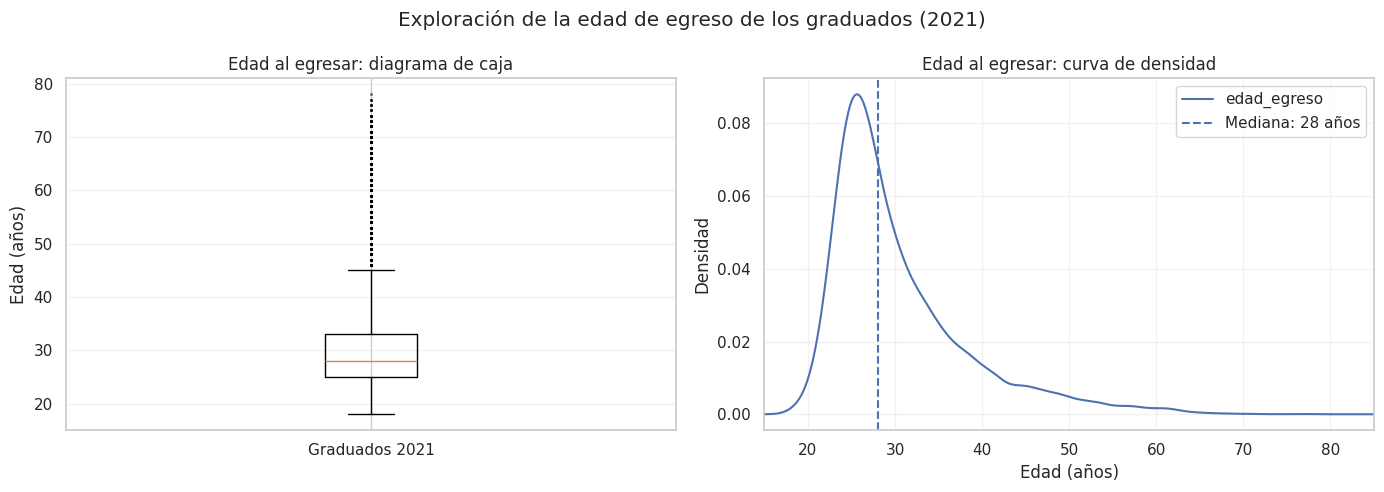

In [154]:
# Muestra exploratoria: una observación por graduado, año 2021.
# No reemplazamos ni eliminamos registros de df_limpio.
df_exploracion = (
    df_limpio.loc[df_limpio['anio'] == 2021]
    .drop_duplicates(subset='id')
    .copy()
)

edad_valida = df_exploracion['edad_egreso'].between(18, 85)
edades = df_exploracion.loc[edad_valida, 'edad_egreso'].dropna()

# Estadísticos calculados sobre TODAS las edades válidas, no sobre una muestra.
print('Total de graduados observados en 2021:', len(df_exploracion))
print('Graduados con edad de egreso entre 18 y 85 años:', len(edades))
print('Graduados fuera de ese rango:', (~edad_valida).sum())
print('Mediana:', edades.median(), 'años')
print('Cuartil 1:', edades.quantile(0.25), 'años')
print('Cuartil 3:', edades.quantile(0.75), 'años')

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# Boxplot de edad (todos los registros válidos).
ax1.boxplot(edades, flierprops={'marker': '.', 'markersize': 2, 'alpha': 0.35})
ax1.set_title('Edad al egresar: diagrama de caja')
ax1.set_ylabel('Edad (años)')
ax1.set_xticks([1], ['Graduados 2021'])
ax1.grid(axis='y', alpha=0.25)

# La densidad se estima sobre una muestra fija para agilizar Colab.
edades_kde = edades.sample(n=min(20000, len(edades)), random_state=42)
edades_kde.plot(kind='density', ax=ax2)
ax2.axvline(edades.median(), linestyle='--', linewidth=1.5,
            label=f'Mediana: {edades.median():.0f} años')
ax2.set_title('Edad al egresar: curva de densidad')
ax2.set_xlabel('Edad (años)')
ax2.set_ylabel('Densidad')
ax2.set_xlim(15, 85)
ax2.legend()
ax2.grid(alpha=0.25)

plt.suptitle('Exploración de la edad de egreso de los graduados (2021)')
plt.tight_layout()
plt.show()

#### Interpretación de la edad de egreso

En el **boxplot** observamos una mediana de **28 años**. El 50 % central de los graduados se ubica entre los **25 años (Q1)** y los **33 años (Q3)**, por lo que una gran parte egresa durante la adultez joven. También se observan edades superiores a las del intervalo central, algunas de ellas marcadas como posibles valores atípicos según el criterio estadístico del boxplot.

La **curva de densidad** presenta su concentración principal en torno a los **25–30 años** y una cola hacia la derecha: a medida que aumenta la edad, los egresos son menos frecuentes. Por lo tanto, la distribución no es simétrica y hay graduados que concluyen sus estudios a edades más avanzadas.

**Importante:** un punto marcado como atípico **no implica necesariamente un error**; egresar a una edad mayor es perfectamente posible. Los límites de 18 y 85 años se utilizan aquí como criterio explícito de análisis, no como prueba de que todas las edades incluidas sean correctas. Esta exploración ayuda a justificar el uso de **tramos de edad en ID3** y de medidas como la mediana para describir la distribución.

### Visualización de salarios en 2021: boxplot y densidad

El salario es una variable central para estudiar las remuneraciones registradas y construir perfiles con K-Means. Antes de modelar, es importante conocer su dispersión y detectar si tiene valores extremos que puedan afectar las distancias entre observaciones.

Se utilizan solo los salarios positivos de 2021, entre graduados con edad válida. Esto evita mezclar importes de 2019, 2020 y 2021, que están expresados en pesos nominales de distintos años. Los salarios faltantes se excluyen solamente del análisis de importes: un dato faltante no se interpreta como un sueldo igual a cero ni prueba que la persona no tenga trabajo.

Debido a que los salarios tienen una cola muy larga hacia valores altos, ambos gráficos usan `log(1 + salario)` para que el cuerpo principal de la distribución sea legible.

Registros de 2021 con salario positivo y edad válida: 162897
Salario mediano: $119,288.87
Salario promedio: $145,898.92
Cuartil 1 (Q1): $78,502.60
Cuartil 3 (Q3): $181,833.20
Salario máximo observado: $8,444,075.00


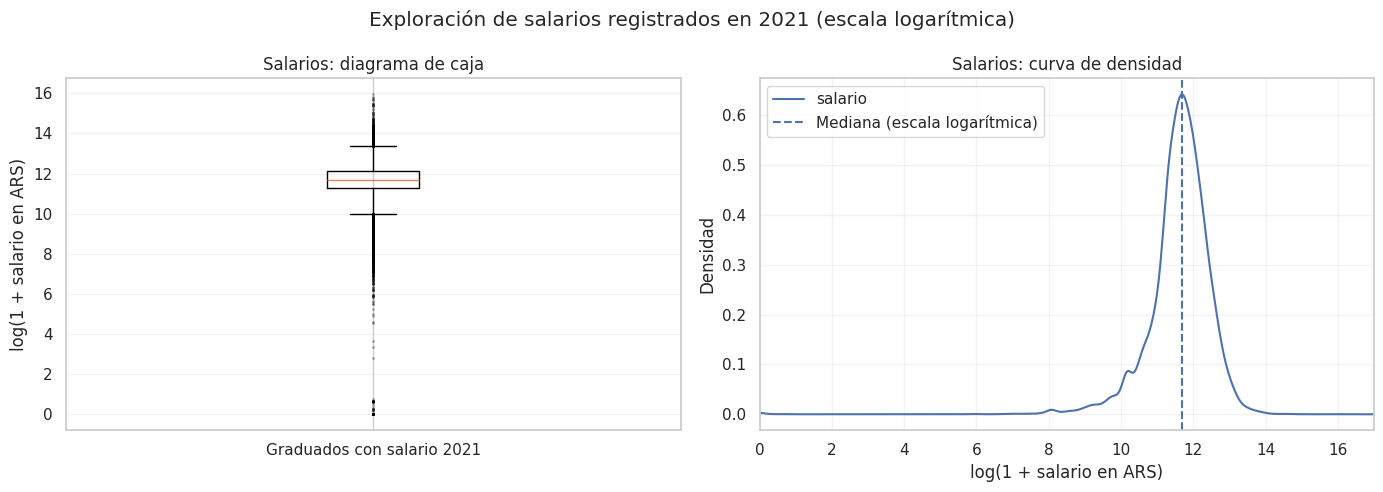

In [155]:
# Mismos graduados de 2021 del análisis anterior, con edad válida
# y salario estrictamente positivo.
salarios = df_exploracion.loc[
    edad_valida & df_exploracion['salario'].gt(0), 'salario'
].dropna()
log_salarios = np.log1p(salarios)

print('Registros de 2021 con salario positivo y edad válida:', len(salarios))
print(f'Salario mediano: ${salarios.median():,.2f}')
print(f'Salario promedio: ${salarios.mean():,.2f}')
print(f'Cuartil 1 (Q1): ${salarios.quantile(0.25):,.2f}')
print(f'Cuartil 3 (Q3): ${salarios.quantile(0.75):,.2f}')
print(f'Salario máximo observado: ${salarios.max():,.2f}')

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# Diagrama de caja del salario transformado para que se vea la dispersión.
ax1.boxplot(log_salarios, flierprops={'marker': '.', 'markersize': 2, 'alpha': 0.3})
ax1.set_title('Salarios: diagrama de caja')
ax1.set_ylabel('log(1 + salario en ARS)')
ax1.set_xticks([1], ['Graduados con salario 2021'])
ax1.grid(axis='y', alpha=0.25)

# Curva de densidad sobre una muestra reproducible para agilizar Colab.
log_salarios_kde = log_salarios.sample(
    n=min(20000, len(log_salarios)), random_state=42
)
log_salarios_kde.plot(kind='density', ax=ax2)
ax2.axvline(np.log1p(salarios.median()), linestyle='--', linewidth=1.5,
            label='Mediana (escala logarítmica)')
ax2.set_title('Salarios: curva de densidad')
ax2.set_xlabel('log(1 + salario en ARS)')
ax2.set_ylabel('Densidad')
ax2.set_xlim(0, 17)  # Zoom legible sobre el rango de los salarios positivos
ax2.legend()
ax2.grid(alpha=0.25)

plt.suptitle('Exploración de salarios registrados en 2021 (escala logarítmica)')
plt.tight_layout()
plt.show()

#### Interpretación de los salarios registrados

Entre los graduados de **2021** con edad válida y salario positivo se observan **162.897 registros**. El **salario mediano es de aproximadamente $119.289** y el **promedio, $145.899**. La media supera a la mediana, lo que, junto con los valores extremos, es consistente con una distribución asimétrica hacia ingresos más altos.

El **boxplot** muestra dispersión y observaciones alejadas del centro de los datos. La **curva de densidad** permite visualizar con más claridad dónde se concentra la mayoría de los salarios después de aplicar la transformación logarítmica. Los valores extremos no desaparecen: simplemente quedan representados en una escala que facilita la lectura.

Estos resultados justifican dos decisiones para **K-Means**: trabajar con salarios de **un mismo año** y utilizar `log(1 + salario)` al calcular las distancias. Así se reduce el peso excesivo que podrían tener los importes más altos. **No debemos eliminar automáticamente los outliers**, ya que algunos podrían corresponder a remuneraciones efectivamente registradas; primero habría que verificar su plausibilidad con el origen de los datos.

*Los montos son nominales de 2021 y no representan salarios actuales. Los resultados describen a graduados con salario observado, no a la totalidad de graduados.*

#### Síntesis del análisis exploratorio

Los gráficos muestran que la edad de egreso se concentra en edades jóvenes, aunque con una cola hacia edades mayores, y que los salarios presentan una dispersión considerable. Conocer estas distribuciones nos ayuda a **justificar las transformaciones que aplicaremos después**, en lugar de elegirlas arbitrariamente: para **ID3**, discretizaremos la edad; para **K-Means**, trabajaremos con un mismo año de salarios y una transformación logarítmica.

A continuación continuamos con la comparación descriptiva de salarios por género y, luego, con las técnicas de aprendizaje automático.


###Visualización del salario promedio por género

Como parte de la exploración de las posibles diferencias en remuneraciones, comparamos los salarios registrados según la variable `genero`. Esta comparación se hace solo entre los graduados de 2021 con edad válida (18 a 85 años) y salario positivo, usando una única observación por `id`.
Calculamos tanto la media como la mediana: la primera permite comparar los promedios y la segunda es menos sensible a salarios excepcionalmente altos. También mostramos el número de personas en cada grupo, ya que las cantidades no son iguales.

A partir de `df_exploracion`, que ya incluye solamente registros de 2021 sin duplicar personas, filtramos la misma población que se utilizó para el boxplot salarial: edades válidas y salarios mayores que cero. Luego agrupamos por género para calcular cantidad de personas, salario promedio y salario mediano.


In [156]:
# edad de egreso válida y remuneración positiva.
df_genero_salario = df_exploracion.loc[
    df_exploracion['edad_egreso'].between(18, 85)
    & df_exploracion['salario'].gt(0)
].copy()

salario_por_genero = (
    df_genero_salario.groupby('genero', as_index=False)
    .agg(
        Personas=('id', 'nunique'),
        Salario_promedio=('salario', 'mean'),
        Salario_mediano=('salario', 'median')
    )
)

print('Graduados incluidos en la comparación:', len(df_genero_salario))
display(salario_por_genero.round(2))

promedios_genero = salario_por_genero.set_index('genero')['Salario_promedio']
if {'mujer', 'varon'}.issubset(promedios_genero.index):
    diferencia_abs = promedios_genero['varon'] - promedios_genero['mujer']
    diferencia_pct = diferencia_abs / promedios_genero['varon'] * 100
    print(f'Diferencia de promedios (varón - mujer): ${diferencia_abs:,.2f}')
    print(f'Promedio de mujeres por debajo del de varones: {diferencia_pct:.1f}%')

Graduados incluidos en la comparación: 162897


,genero,Personas,Salario_promedio,Salario_mediano
0,mujer,96428,130710.78,109505.96
1,varon,66469,167932.67,136086.80


Diferencia de promedios (varón - mujer): $37,221.89
Promedio de mujeres por debajo del de varones: 22.2%


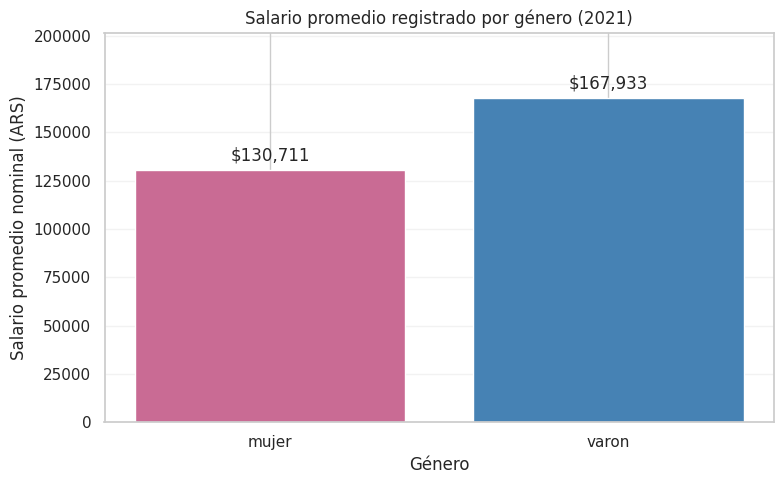

In [157]:
import matplotlib.pyplot as plt
import seaborn as sns

# Mantener las mismas categorías del diccionario y mostrar pesos nominales de 2021.
orden_genero = ['mujer', 'varon']
colores = {'mujer': '#C96B94', 'varon': '#4682B4'}
tabla_grafico = salario_por_genero.set_index('genero').reindex(orden_genero).dropna(
    subset=['Salario_promedio']
)

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(
    tabla_grafico.index,
    tabla_grafico['Salario_promedio'],
    color=[colores[g] for g in tabla_grafico.index]
)
ax.bar_label(barras,
             labels=[f'${valor:,.0f}' for valor in tabla_grafico['Salario_promedio']],
             padding=4)
ax.set_title('Salario promedio registrado por género (2021)')
ax.set_xlabel('Género')
ax.set_ylabel('Salario promedio nominal (ARS)')
ax.set_ylim(0, tabla_grafico['Salario_promedio'].max() * 1.20)
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

#### Interpretación del salario promedio por género

En el grupo de 162.897 graduados con salario positivo en 2021, se observan 96.428 mujeres y 66.469 varones. El salario promedio registrado es de $130.711 para las mujeres y de $167.933 para los varones.

El gráfico muestra una diferencia de aproximadamente $37.222 mensuales entre ambos promedios. Tomando como referencia el promedio de los varones, el de las mujeres es 22.2% menor. La diferencia también se observa en las medianas: $109.506 para mujeres frente a $136.087 para varones, una diferencia de aproximadamente $26.581. Esto indica que el resultado no depende únicamente de unos pocos salarios muy altos que elevan el promedio.

Interpretación y alcance: se trata de una diferencia descriptiva, sin ajuste por otras variables. Los grupos pueden tener distintas composiciones de rama de estudio, región, tipo de título, edad, actividad laboral, jornada u otras características no controladas. Por eso, esta comparación no demuestra por sí sola una diferencia salarial por el mismo trabajo ni que el género sea la causa de la brecha.

El hallazgo es relevante para el objetivo general del trabajo porque señala una diferencia que podría investigarse con análisis más específicos, por ejemplo comparando salarios por género dentro de una misma rama y región.

# 5. Aplicación de técnicas de aprendizaje automático

## Técnica 1: Árbol de decisión con algoritmo ID3

**Objetivo:** estudiar qué características académicas y demográficas se relacionan con la presencia de un **salario registrado** en la base.

La variable objetivo toma el valor 1 cuando `salario` no es nulo y 0 cuando es nulo. **La ausencia de salario no equivale necesariamente a desempleo**: puede indicar ausencia de remuneración asalariada registrada en esta fuente.

Implementamos ID3 explícitamente: calcula **entropía**, utilizala **ganancia de información** y divide por **cada categoría** del atributo elegido. El árbol esta limitado en profundidad para facilitar la interpretación y reducir el sobreajuste.

### Paso 1. Preparar las características

ID3 trabaja con atributos categóricos. Conservamos `rama`, `tipo_titulo`, `gestion`, `genero` y `region`; transformamos `edad_egreso` en intervalos. No utilizamos `salario` entre las variables predictoras, ya que de esa misma columna derivamos la variable objetivo.

Separamos los conjuntos de entrenamiento y prueba **por identificador de graduado** para que una persona no aparezca en ambos conjuntos. Entrenamos con una muestra estratificada de hasta 40.000 registros, ya que la implementación recursiva es didáctica y el dataset original es muy grande; evaluamos sobre todo el conjunto reservado para prueba.

In [158]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.metrics import classification_report, accuracy_score, ConfusionMatrixDisplay
from IPython.display import display
import matplotlib.pyplot as plt

# 1 si hay remuneración registrada; 0 si no figura en esta fuente
df_limpio['salario_registrado'] = df_limpio['salario'].notna().astype(int)

es_edad_valida = df_limpio['edad_egreso'].between(18, 85)

df_id3 = df_limpio.loc[
    es_edad_valida,
    [
        'id', 'rama', 'tipo_titulo',
        'gestion', 'genero', 'region',
        'edad_egreso', 'salario_registrado'
    ]
].copy()

# Discretizamos la edad: ID3 divide por categorías.
df_id3['tramo_edad'] = pd.cut(
    df_id3['edad_egreso'],
    bins=[18, 25, 30, 35, 40, 50, 86],
    labels=['18-24', '25-29', '30-34', '35-39', '40-49', '50-85'],
    right=False
)

atributos = ['rama', 'tipo_titulo', 'gestion', 'genero', 'region', 'tramo_edad']
for col in atributos:
    df_id3[col] = df_id3[col].astype('string').fillna('Sin dato')

# La misma persona nunca queda en entrenamiento y en prueba.
separador = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
indices_train, indices_test = next(
    separador.split(df_id3, groups=df_id3['id'])
)
datos_train = df_id3.iloc[indices_train]
datos_test = df_id3.iloc[indices_test]

# Muestra estratificada del conjunto de entrenamiento para acelerar ID3.
if len(datos_train) > 40000:
    datos_train_id3, _ = train_test_split(
        datos_train, train_size=40000, random_state=42,
        stratify=datos_train['salario_registrado']
    )
else:
    datos_train_id3 = datos_train.copy()

print('Registros de entrenamiento usados por ID3:', len(datos_train_id3))
print('Registros de prueba (no utilizados para entrenar):', len(datos_test))
print('Proporciones de clase en entrenamiento:')
print(datos_train_id3['salario_registrado'].value_counts(normalize=True))
print('Proporciones de clase en prueba:')
print(datos_test['salario_registrado'].value_counts(normalize=True))
display(datos_train_id3[atributos + ['salario_registrado']].head())

Registros de entrenamiento usados por ID3: 40000
Registros de prueba (no utilizados para entrenar): 164055
Proporciones de clase en entrenamiento:
salario_registrado
1    0.5832
0    0.4168
Name: proportion, dtype: float64
Proporciones de clase en prueba:
salario_registrado
1    0.584901
0    0.415099
Name: proportion, dtype: float64


,rama,tipo_titulo,gestion,genero,region,tramo_edad,salario_registrado
795025,Ciencias Humanas,Grado y profesorado,privada,mujer,CABA,18-24,0
82516,Ciencias Sociales,Grado y profesorado,estatal,mujer,"RESTO PAMPEANA (SANTA FE, CORDOBA, ENTRE RIOS,...",40-49,0
332904,Ciencias Básicas,Posgrado,estatal,varon,"RESTO PAMPEANA (SANTA FE, CORDOBA, ENTRE RIOS,...",25-29,1
452024,Ciencias de la Salud,Tecnicatura,estatal,mujer,NOA,25-29,0
462819,Ciencias Humanas,Grado y profesorado,estatal,mujer,CABA,25-29,0


### Paso 2. Entropía y ganancia de información

La **entropía** mide cuánta incertidumbre hay sobre la clase que queremos predecir. Si todos los registros tienen la misma clase, la entropía es 0.

La **ganancia de información** mide cuánto disminuye la entropía al separar los datos según un atributo. **ID3 elige el atributo que obtiene la mayor ganancia**, y vuelve a repetir el procedimiento en cada rama.


In [159]:
def entropia(clases):
    # Probabilidades de cada clase; nunca pasamos probabilidades 0 a log2.
    probabilidades = clases.value_counts(normalize=True)
    return float(-(probabilidades * np.log2(probabilidades)).sum())


def ganancia_informacion(datos, atributo, objetivo='salario_registrado'):
    entropia_antes = entropia(datos[objetivo])
    entropia_despues = 0.0

    # En ID3, cada categoría forma una rama distinta.
    for _, subconjunto in datos.groupby(atributo, sort=False):
        peso = len(subconjunto) / len(datos)
        entropia_despues += peso * entropia(subconjunto[objetivo])

    return entropia_antes - entropia_despues


# Mostramos el cálculo de ganancia para la primera decisión del árbol.
ganancias_raiz = pd.Series({
    atributo: ganancia_informacion(datos_train_id3, atributo)
    for atributo in atributos
}).sort_values(ascending=False)

print('Entropía inicial:', round(entropia(datos_train_id3['salario_registrado']), 4))
print('Ganancias de información en la raíz:')
display(ganancias_raiz.rename('Ganancia de información').to_frame())
print('Atributo con mayor ganancia:', ganancias_raiz.index[0])

Entropía inicial: 0.9799
Ganancias de información en la raíz:


,Ganancia de información
tramo_edad,0.016317
region,0.016087
tipo_titulo,0.006930
rama,0.004702
genero,0.001138
gestion,0.000429


Atributo con mayor ganancia: tramo_edad


### Paso 3. Construir el árbol ID3 recursivamente

En cada nodo se busca la variable de mayor ganancia, se crea una rama por cada categoría observada y se repite el proceso con los atributos restantes. Se detiene si todos los registros son de una sola clase, ya no quedan variables o se alcanza el límite de profundidad o tamaño mínimo.

Cada hoja guarda la clase mayoritaria y la proporción de salarios registrados. Si durante la predicción aparece una categoría que nunca estuvo en una rama del entrenamiento, usamos la clase mayoritaria del último nodo conocido.

In [160]:
def construir_id3(datos, disponibles, profundidad=0,
                  max_profundidad=3, min_ejemplos=300, ganancia_minima=0.0001):
    y_nodo = datos['salario_registrado']
    nodo = {
        'atributo': None,
        'prediccion': int(y_nodo.value_counts().idxmax()),
        'cantidad': len(datos),
        'proporcion_1': float(y_nodo.mean()),
        'ramas': {}
    }

    # Condiciones de parada para no generar un árbol enorme.
    if (y_nodo.nunique() == 1 or not disponibles or
            profundidad >= max_profundidad or len(datos) < min_ejemplos):
        return nodo

    ganancias = {
        atributo: ganancia_informacion(datos, atributo)
        for atributo in disponibles
    }
    mejor = max(ganancias, key=ganancias.get)
    if ganancias[mejor] <= ganancia_minima:
        return nodo

    nodo['atributo'] = mejor
    nodo['ganancia'] = float(ganancias[mejor])
    restantes = [atributo for atributo in disponibles if atributo != mejor]

    for valor, subconjunto in datos.groupby(mejor, sort=True):
        nodo['ramas'][str(valor)] = construir_id3(
            subconjunto, restantes, profundidad + 1,
            max_profundidad, min_ejemplos, ganancia_minima
        )
    return nodo


def predecir_id3(arbol, registro):
    nodo = arbol
    while nodo['atributo'] is not None:
        valor = str(registro[nodo['atributo']])
        if valor not in nodo['ramas']:
            return nodo['prediccion']
        nodo = nodo['ramas'][valor]
    return nodo['prediccion']


arbol_id3 = construir_id3(datos_train_id3, atributos, max_profundidad=3,
                          min_ejemplos=300)
print('Atributo elegido en la raíz:', arbol_id3['atributo'])
print('Ganancia en la raíz:', round(arbol_id3.get('ganancia', 0), 5))

Atributo elegido en la raíz: tramo_edad
Ganancia en la raíz: 0.01632


### Paso 4. Evaluar el árbol con datos no utilizados en el entrenamiento

Usamos las mismas métricas que en el árbol original, pero **los valores pueden cambiar**, porque ahora se usa un algoritmo diferente, una muestra de entrenamiento y una separación por persona. Comparamos también contra la exactitud que se obtendría prediciendo siempre la clase mayoritaria.

In [161]:
# Aplicamos las reglas aprendidas a todo el conjunto de prueba.
X_test_id3 = datos_test[atributos]
y_test_id3 = datos_test['salario_registrado']

predicciones_id3 = np.fromiter(
    (predecir_id3(arbol_id3, dict(zip(atributos, fila)))
     for fila in X_test_id3.itertuples(index=False, name=None)),
    dtype=int,
    count=len(X_test_id3)
)

print('--- REPORTE DE CLASIFICACIÓN: ID3 ---')
print(classification_report(y_test_id3, predicciones_id3,
                            labels=[0, 1], zero_division=0,
                            target_names=['Sin salario registrado', 'Con salario registrado']))
print('Accuracy ID3:', round(accuracy_score(y_test_id3, predicciones_id3), 4))
print('Accuracy base (clase mayoritaria):',
      round(y_test_id3.value_counts(normalize=True).max(), 4))

--- REPORTE DE CLASIFICACIÓN: ID3 ---
                        precision    recall  f1-score   support

Sin salario registrado       0.55      0.42      0.47     68099
Con salario registrado       0.65      0.75      0.70     95956

              accuracy                           0.61    164055
             macro avg       0.60      0.59      0.58    164055
          weighted avg       0.60      0.61      0.60    164055

Accuracy ID3: 0.614
Accuracy base (clase mayoritaria): 0.5849


### Paso 5. Visualizaciones del proceso y del resultado

El primer gráfico explica **por qué ID3 eligió la variable de la raíz**. El segundo muestra sus aciertos y errores. Por último, el árbol multicategoría.

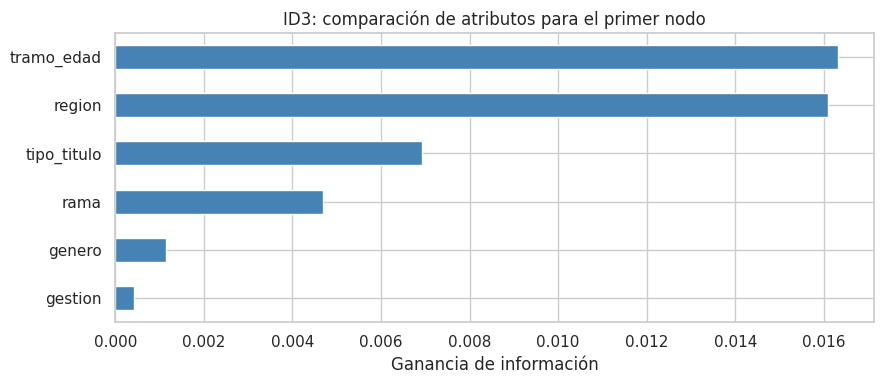

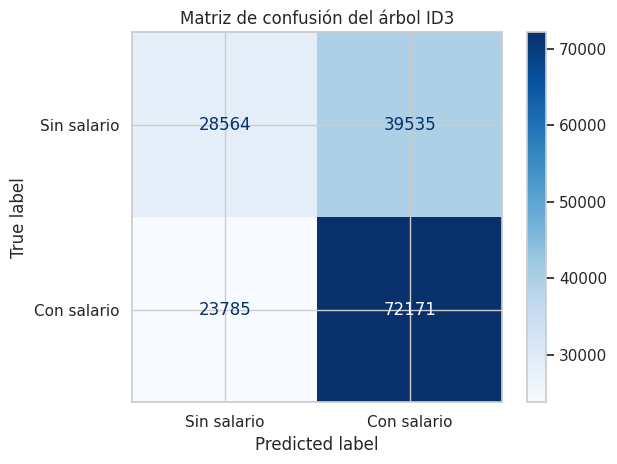

In [162]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(9, 4))
ganancias_raiz.sort_values().plot(kind='barh', color='#4682b4')
plt.xlabel('Ganancia de información')
plt.title('ID3: comparación de atributos para el primer nodo')
plt.tight_layout()
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test_id3, predicciones_id3,
    labels=[0, 1],
    display_labels=['Sin salario', 'Con salario'],
    cmap='Blues', values_format='d'
)
plt.title('Matriz de confusión del árbol ID3')
plt.tight_layout()
plt.show()

####Análisis de la ganancia de información

El gráfico de ganancia de información permite identificar cuáles de las variables seleccionadas contribuyen en mayor medida a reducir la incertidumbre sobre la existencia de un salario registrado.

Se observa que el tramo de edad presenta la ganancia más elevada (0,01632), seguido muy de cerca por la región (0,01609). Por esta razón, ID3 selecciona el tramo de edad como atributo inicial del árbol.

En cambio, variables como género (0,00114) y tipo de gestión de la institución (0,00043) presentan ganancias considerablemente menores en esta primera evaluación.

Sin embargo, las ganancias obtenidas son relativamente bajas respecto de la entropía inicial (0,9799). Esto indica que ninguna de las características consideradas permite, individualmente, distinguir de manera precisa los registros con salario de aquellos sin salario.

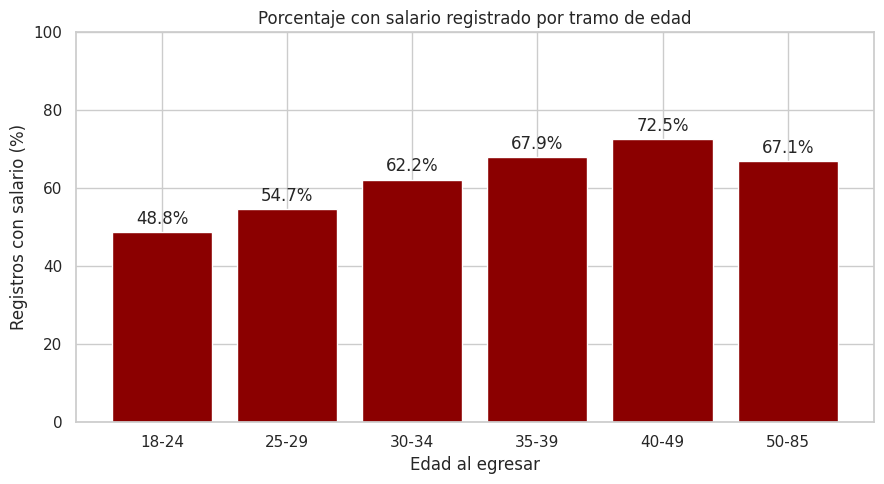

In [163]:
orden_edad = ['18-24', '25-29', '30-34',
              '35-39', '40-49', '50-85']

resumen_edad = (
    datos_train_id3.groupby('tramo_edad')['salario_registrado']
    .agg(['mean', 'size'])
    .reindex(orden_edad)
)

porcentajes = resumen_edad['mean'] * 100

plt.figure(figsize=(9, 5))
barras = plt.bar(
    porcentajes.index,
    porcentajes.values,
    color='darkred'
)

plt.bar_label(barras, fmt='%.1f%%', padding=3)
plt.ylim(0, 100)
plt.xlabel('Edad al egresar')
plt.ylabel('Registros con salario (%)')
plt.title('Porcentaje con salario registrado por tramo de edad')
plt.tight_layout()
plt.show()

El grafico muestra una tendencia creciente entre los 18 y los 49 años, seguida de una disminución en el último intervalo.

Esto nos permite entender por qué el algoritmo encontró información útil en el tramo de edad, aunque no demuestra que la edad sea la causa del resultado laboral.



####Evaluación del modelo y matriz de confusión

Para evaluar el rendimiento del algoritmo se utilizó un conjunto de 164.055 registros, separado del entrenamiento por identificador de graduado.

El modelo obtuvo una exactitud global del 61,40%, superando el 58,49% que se obtendría clasificando todos los casos dentro de la clase mayoritaria.

La matriz de confusión muestra que el algoritmo clasificó correctamente 72.171 registros con salario y 28.564 registros sin salario. Sin embargo, también clasificó incorrectamente 39.535 casos sin salario como si tuvieran uno, y 23.785 casos con salario como si no lo tuvieran.

Al evaluar las clases por separado, el modelo alcanzó un recall del 75,2% para los registros con salario y del 41,9% para aquellos sin salario.

Estos resultados indican que el algoritmo tiene mayor capacidad para identificar registros con salario que registros sin salario. Aunque la exactitud supera a la clasificación por clase mayoritaria, la mejora es limitada. Por lo tanto, el modelo resulta más útil para explorar relaciones entre las características de los graduados que para realizar predicciones individuales confiables.

In [164]:
# Visualizamos el árbol categórico de ID3
niveles_a_mostrar = 3
ancho_vista_px = 6600 if niveles_a_mostrar == 2 else 33300
alto_vista_px = 700

from graphviz import Digraph
from IPython.display import display, HTML
import base64

grafo_id3 = Digraph('Arbol_ID3', format='svg')
grafo_id3.attr(rankdir='TB')
contador = [0]

def graficar_nodo(nodo, padre=None, etiqueta_rama=None, nivel=0, max_nivel=2):
    nombre = f'n{contador[0]}'
    contador[0] += 1
    atributo = nodo['atributo']
    valor = 'Sí' if nodo['prediccion'] == 1 else 'No'

    if atributo is None:
        texto = f"Hoja: {valor}\nN={nodo['cantidad']}\nP(salario)={nodo['proporcion_1']:.1%}"
        grafo_id3.node(nombre, texto, shape='ellipse', style='filled', fillcolor='lightyellow')
    elif nivel >= max_nivel:
        texto = f"{atributo} (continúa)\nN={nodo['cantidad']}\nP(salario)={nodo['proporcion_1']:.1%}"
        grafo_id3.node(nombre, texto, shape='box', style='filled', fillcolor='lightgray')
    else:
        texto = f"{atributo}\nN={nodo['cantidad']}\nGanancia={nodo['ganancia']:.4f}"
        grafo_id3.node(nombre, texto, shape='box', style='filled', fillcolor='lightblue')

    if padre is not None:
        grafo_id3.edge(padre, nombre, label=str(etiqueta_rama))
    if atributo is not None and nivel < max_nivel:
        for valor_rama, hijo in nodo['ramas'].items():
            graficar_nodo(hijo, nombre, valor_rama, nivel + 1, max_nivel)

graficar_nodo(arbol_id3, max_nivel=niveles_a_mostrar)

# SVG mantiene la nitidez al agrandar o reducir, a diferencia de PNG.
svg_bytes = grafo_id3.pipe(format='svg')
src_svg = base64.b64encode(svg_bytes).decode('ascii')

# El tamaño es el de la imagen, no el del modelo; se puede modificar libremente.
display(HTML(f"""
<div style='width:100%; height:{alto_vista_px}px; overflow:auto; border:1px solid #cbd5e1; border-radius:8px;'>
  <img src='data:image/svg+xml;base64,{src_svg}'
       style='width:{ancho_vista_px}px; max-width:none; display:block; height:auto;'/>
</div>
<p style='font-size:12px;color:#64748b;'>Desplazate horizontalmente para recorrer todas las ramas.</p>
"""))


####Interpretación del árbol de decisión

El árbol construido mediante ID3 permite visualizar cómo se combinan las características de los graduados para identificar patrones relacionados con la presencia de remuneraciones registradas.

La primera división se realiza a partir del tramo de edad al egresar. Posteriormente, el algoritmo selecciona distintas características según el subconjunto analizado.

Para los graduados que finalizaron sus estudios entre los 18 y 34 años, el siguiente atributo seleccionado es la región. En cambio, para los grupos de 35 a 49 años, el árbol utiliza la rama de estudio y, para el grupo de 50 a 85 años, el tipo de título.

Esto sugiere que las características más útiles para clasificar los registros no son necesariamente las mismas en todos los grupos etarios.

Como ejemplo, entre los graduados de 25 a 29 años, el 68,1% de los registros correspondientes a CABA presenta salario registrado, frente al 51,4% de los correspondientes a Buenos Aires, dentro de la muestra utilizada para entrenar el algoritmo.

Esta diferencia representa una asociación observable en los datos, pero no permite establecer una relación causal entre la región y la situación laboral.

###Conclusión de la técnica ID3

La aplicación de ID3 permitió identificar patrones entre las características académicas y demográficas de los graduados y la presencia de remuneraciones registradas.

El análisis destacó principalmente el tramo de edad y la región como atributos útiles para la clasificación inicial. Asimismo, permitió observar que la rama de estudio y el tipo de título adquieren relevancia en determinados grupos de edad.

No obstante, el rendimiento predictivo fue moderado, con una mejora limitada respecto de la clasificación por clase mayoritaria. Esto sugiere que las variables disponibles no son suficientes para explicar completamente la presencia o ausencia de remuneraciones registradas.

Además, debe considerarse que la falta de un salario en el dataset no implica necesariamente que una persona esté desempleada, sino que no se dispone de una remuneración registrada en la fuente utilizada.

En conclusión, ID3 resultó útil principalmente como herramienta de análisis exploratorio e interpretación de patrones, al permitir visualizar de manera comprensible las reglas de clasificación generadas a partir de los datos.

## Técnica 2: Segmentación de graduados con K-Means

**Objetivo:** identificar perfiles de graduados según su remuneración registrada, edad al egresar y características académicas y demográficas. A diferencia de ID3, K-Means es no supervisado: buscamos agrupar observaciones que se parecen según las variables elegidas.

Analizamos registros solo del año 2021. Esto evita comparar directamente salarios de 2019, 2020 y 2021 (afectados por el cambio en el valor de la moneda en nuestro país) y evita contar tres veces a una persona por los distintos relevamientos. El análisis describe exclusivamente a quienes tienen salario informado, no a todos los graduados.

### Paso 1. Selección de registros y controles de calidad

Conservamos observaciones de **2021**, con `salario > 0` y `edad_egreso` entre **18 y 85 años**. Revisamos la cantidad de personas únicas, los valores faltantes en las características que utilizaremos y la distribución salarial. El límite de edad es una decisión de limpieza y puede excluir casos legítimos fuera de ese intervalo.

In [165]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Mismo período para todas las personas: salarios nominales de 2021.
mascara_km = (
    (df_limpio['anio'] == 2021)
    & df_limpio['edad_egreso'].between(18, 85)
    & df_limpio['salario'].gt(0)
)
df_kmeans = df_limpio.loc[mascara_km].drop_duplicates(subset='id').copy()

numericas_km = ['log_salario', 'edad_egreso']
categoricas_km = ['rama', 'tipo_titulo', 'gestion', 'genero', 'region']

print('Registros incluidos:', len(df_kmeans))
print('Personas únicas:', df_kmeans['id'].nunique())
print('Valores faltantes en las variables categóricas:')
display(df_kmeans[categoricas_km].isna().sum().to_frame('Nulos'))
print('Resumen de salarios nominales 2021 (pesos):')
display(df_kmeans['salario'].describe(percentiles=[.10, .50, .90, .99]).round(2).to_frame())

Registros incluidos: 162897
Personas únicas: 162897
Valores faltantes en las variables categóricas:


,Nulos
rama,0
tipo_titulo,0
gestion,0
genero,0
region,0


Resumen de salarios nominales 2021 (pesos):


,salario
count,162897.00
mean,145898.92
std,129294.98
min,0.01
10%,42680.50
50%,119288.87
90%,269145.79
99%,547602.37
max,8444075.00


### Paso 2. Transformación del salario y codificación de las variables

K-Means calcula distancias euclidianas entre registros, de modo que la **escala y la codificación afectan los grupos**.

1. Aplicamos `log1p(salario)` para reducir el efecto de los valores salariales muy altos, sin reemplazar el salario original usado en los informes.
2. Estandarizamos solo las **dos variables numéricas** (`log_salario` y `edad_egreso`) usando `StandardScaler`.
3. Convertimos rama, título, gestión, género y región a indicadores **0/1** con One-Hot Encoding, **sin estandarizar cada indicador**. Esto evita que categorías raras reciban un peso desproporcionado solo por su baja frecuencia.


In [166]:
# Reducimos asimetría de los ingresos sin alterar el salario original.
df_kmeans['log_salario'] = np.log1p(df_kmeans['salario'])

# Estandarización de salario logarítmico y edad.
escalador_km = StandardScaler()
X_num_km = escalador_km.fit_transform(df_kmeans[numericas_km])

# Dummies 0/1: dejamos todas las categorías para conservar la información.
X_cat_km = pd.get_dummies(
    df_kmeans[categoricas_km],
    drop_first=False,
    dtype=float
)

# Representación final para K-Means y PCA.
X_km_scaled = np.hstack([X_num_km, X_cat_km.to_numpy()])
columnas_modelo_km = numericas_km + X_cat_km.columns.tolist()

print('Matriz para K-Means (filas, características):', X_km_scaled.shape)
print('Primeras características:', columnas_modelo_km[:10])
print('Media y desvío de las dos variables numéricas escaladas:')
print(np.round(X_num_km.mean(axis=0), 3), np.round(X_num_km.std(axis=0), 3))

Matriz para K-Means (filas, características): (162897, 23)
Primeras características: ['log_salario', 'edad_egreso', 'rama_Ciencias Aplicadas', 'rama_Ciencias Básicas', 'rama_Ciencias Humanas', 'rama_Ciencias Sociales', 'rama_Ciencias de la Salud', 'rama_Sin Rama', 'tipo_titulo_Grado y profesorado', 'tipo_titulo_Posgrado']
Media y desvío de las dos variables numéricas escaladas:
[ 0. -0.] [1. 1.]


### Paso 3. Método del codo y silueta

Probamos **K entre 1 y 7**. Con el **método del codo**, analizamos la inercia (suma de distancias cuadradas de cada observación a su centroide). La inercia siempre disminuye al aumentar K, por lo que no alcanza por sí sola para elegir una cantidad de grupos.

Como segundo criterio, usamos el **Silhouette Score**, que compara qué tan próxima está cada observación a su propio grupo respecto de otros grupos. Cuanto mayor sea el valor, mejor es la separación; valores cercanos a 0 indican superposición.

Para reducir el tiempo de ejecución de Colab, calculamos ambas métricas sobre **la misma muestra reproducible de 8.000 registros**; para la silueta usamos hasta 1.800 de ellos. Después entrenamos el modelo final sobre **los 162.897 registros filtrados**. Las métricas de esta etapa son estimaciones muestrales.

,K,Inercia,Silhouette Score
0,1,38075.3717,NaN
1,2,32289.6290,0.1757
2,3,28817.8424,0.1253
3,4,26220.6073,0.1381
4,5,25206.3155,0.1017
5,6,24119.0899,0.0981
6,7,23363.7449,0.0939


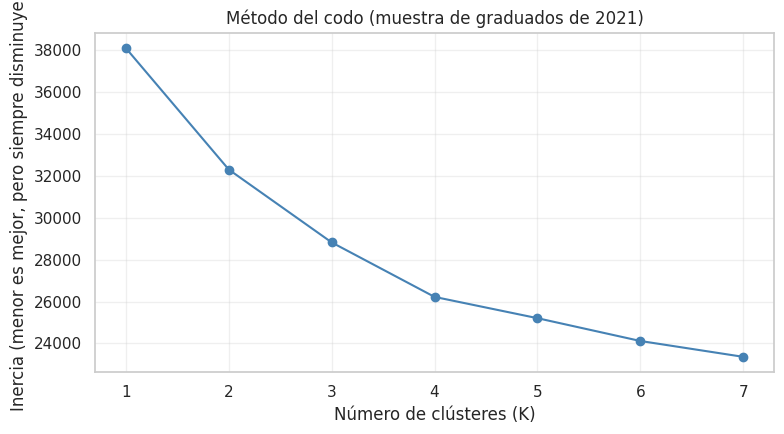

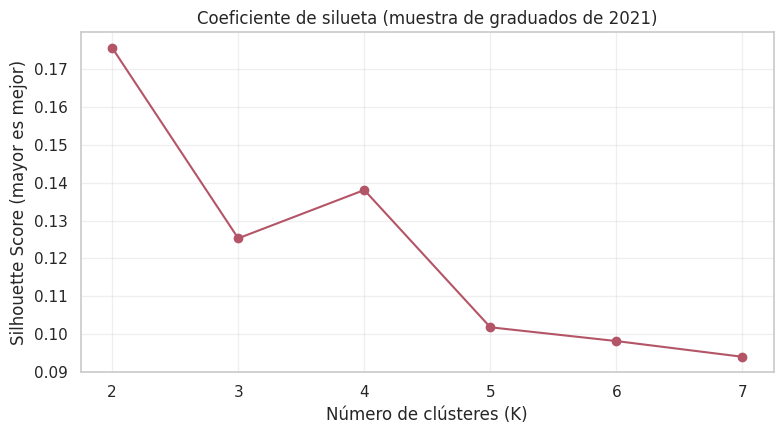

In [167]:
# La matriz de características X_km_scaled ya se preparó sin valores nulos.
# Tomamos una muestra reproducible de 8.000 registros para comparar K.
rng_km = np.random.default_rng(42)
indices_muestra_km = rng_km.choice(
    len(X_km_scaled),
    size=min(8000, len(X_km_scaled)),
    replace=False
)
X_muestra_km = X_km_scaled[indices_muestra_km]

metricas_km = []
for k in range(1, 8):
    modelo_k = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas_k = modelo_k.fit_predict(X_muestra_km)
    silueta_k = np.nan if k == 1 else silhouette_score(
        X_muestra_km, etiquetas_k,
        sample_size=min(1800, len(X_muestra_km)),
        random_state=42
    )
    metricas_km.append({
        'K': k,
        'Inercia': modelo_k.inertia_,
        'Silhouette Score': silueta_k
    })

resultado_metricas_km = pd.DataFrame(metricas_km)
display(resultado_metricas_km.round(4))

plt.figure(figsize=(8, 4.5))
plt.plot(resultado_metricas_km['K'], resultado_metricas_km['Inercia'],
         marker='o', color='#4682b4')
plt.title('Método del codo (muestra de graduados de 2021)')
plt.xlabel('Número de clústeres (K)')
plt.ylabel('Inercia (menor es mejor, pero siempre disminuye)')
plt.xticks(range(1, 8))
plt.grid(alpha=.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4.5))
plt.plot(resultado_metricas_km.loc[resultado_metricas_km['K'] >= 2, 'K'],
         resultado_metricas_km.loc[resultado_metricas_km['K'] >= 2, 'Silhouette Score'],
         marker='o', color='#b45567')
plt.title('Coeficiente de silueta (muestra de graduados de 2021)')
plt.xlabel('Número de clústeres (K)')
plt.ylabel('Silhouette Score (mayor es mejor)')
plt.xticks(range(2, 8))
plt.grid(alpha=.3)
plt.tight_layout()
plt.show()


#### *Elección de K*

En la prueba realizada con la muestra de 8.000 registros, la inercia disminuye progresivamente y no aparece un codo inequívoco. Por su parte, el coeficiente de silueta es aproximadamente 0,176 para K=2, 0,125 para K=3 y 0,138 para K=4. Por este indicador, K=2 es la mejor elección.

Pero utilizamos K=3 como decisión exploratoria porque nos permite comparar tres perfiles con diferencias interpretables de edad y remuneración, aunque K=3 no sea el valor óptimo, lo elegimos por un análisis descriptivo más detallado. Los valores de silueta relativamente bajos anticipan que algunos perfiles pueden superponerse.

### Paso 4. Entrenamiento final de K-Means con K=3

A diferencia de las pruebas muestrales de K, el modelo final se ajusta a todos los registros de 2021 que superaron los filtros. `random_state=42` y `n_init=10` favorecen la reproducibilidad. Los identificadores `0`, `1` y `2` son etiquetas arbitrarias: no representan un orden de calidad.

In [168]:
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
df_kmeans['cluster'] = kmeans_final.fit_predict(X_km_scaled)

# Resumen descriptivo en unidades originales (pesos y años).
perfiles_km = df_kmeans.groupby('cluster').agg(
    Personas=('id', 'nunique'),
    Salario_promedio=('salario', 'mean'),
    Salario_mediano=('salario', 'median'),
    Edad_promedio=('edad_egreso', 'mean')
).sort_index()
perfiles_km['Porcentaje'] = perfiles_km['Personas'] / len(df_kmeans) * 100

print('Cantidad de personas y características numéricas por clúster:')
display(perfiles_km.round(2))

Cantidad de personas y características numéricas por clúster:


,Personas,Salario_promedio,Salario_mediano,Edad_promedio,Porcentaje
cluster,,,,,
0,84639,180344.85,148853.44,27.76,51.96
1,33638,179075.64,147070.94,43.95,20.65
2,44620,55547.78,56297.79,27.99,27.39


### Paso 5. Caracterización de los perfiles y comparaciones gráficas

Para interpretar las agrupaciones no alcanza con conocer el salario y la edad promedio: también estudiamos la distribución porcentual dentro de cada clúster según rama académica, género, gestión universitaria y tipo de título. Estas proporciones describen los grupos encontrados, pero no implican que una característica cause mayor o menor remuneración.

In [169]:
# Porcentajes por fila: dentro de cada clúster suman 100%.
for variable_km in ['rama', 'genero', 'gestion', 'tipo_titulo']:
    porcentajes_var = (
        pd.crosstab(
            df_kmeans['cluster'],
            df_kmeans[variable_km],
            normalize='index'
        ) * 100
    )
    print(f'=== Distribución de {variable_km} por clúster (%) ===')
    display(porcentajes_var.round(1))

# Rama más frecuente y su peso (no confundir con "rama única").
tabla_ramas_km = pd.crosstab(df_kmeans['cluster'], df_kmeans['rama'], normalize='index') * 100
rama_principal_km = tabla_ramas_km.idxmax(axis=1)
porcentaje_rama_km = tabla_ramas_km.max(axis=1)
reporte_perfiles = perfiles_km.copy()
reporte_perfiles['Rama_mas_frecuente'] = rama_principal_km
reporte_perfiles['Porcentaje_de_esa_rama'] = porcentaje_rama_km
print('=== Resumen descriptivo de perfiles ===')
display(reporte_perfiles.round(2))

=== Distribución de rama por clúster (%) ===


rama,Ciencias Aplicadas,Ciencias Básicas,Ciencias Humanas,Ciencias Sociales,Ciencias de la Salud,Sin Rama
cluster,,,,,,
0,29.9,2.1,6.8,46.8,14.3,0.1
1,13.5,1.7,22.5,41.1,21.2,0.0
2,16.7,4.5,25.8,32.3,20.1,0.6


=== Distribución de genero por clúster (%) ===


genero,mujer,varon
cluster,,
0,48.0,52.0
1,61.6,38.4
2,78.7,21.3


=== Distribución de gestion por clúster (%) ===


gestion,estatal,privada
cluster,,
0,79.5,20.5
1,75.7,24.3
2,85.5,14.5


=== Distribución de tipo_titulo por clúster (%) ===


tipo_titulo,Grado y profesorado,Posgrado,Pregrado y títulos intermedios,Tecnicatura
cluster,,,,
0,77.6,4.5,7.6,10.3
1,55.8,21.3,6.3,16.6
2,72.9,3.1,9.5,14.5


=== Resumen descriptivo de perfiles ===


,Personas,Salario_promedio,Salario_mediano,Edad_promedio,Porcentaje,Rama_mas_frecuente,Porcentaje_de_esa_rama
cluster,,,,,,,
0,84639,180344.85,148853.44,27.76,51.96,Ciencias Sociales,46.78
1,33638,179075.64,147070.94,43.95,20.65,Ciencias Sociales,41.06
2,44620,55547.78,56297.79,27.99,27.39,Ciencias Sociales,32.25


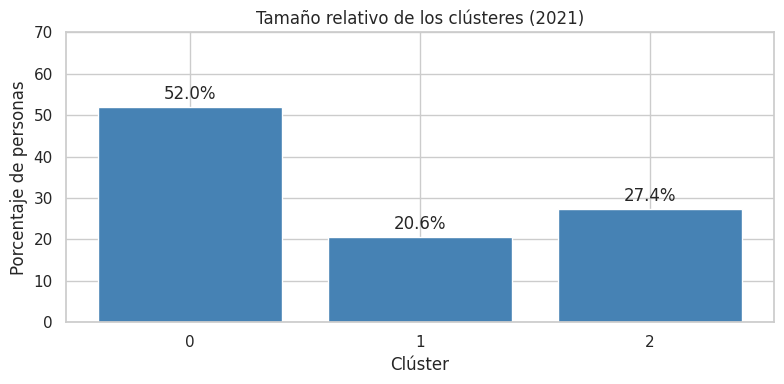

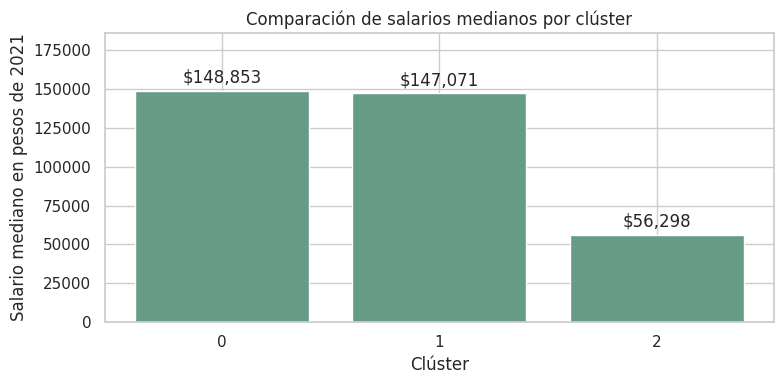

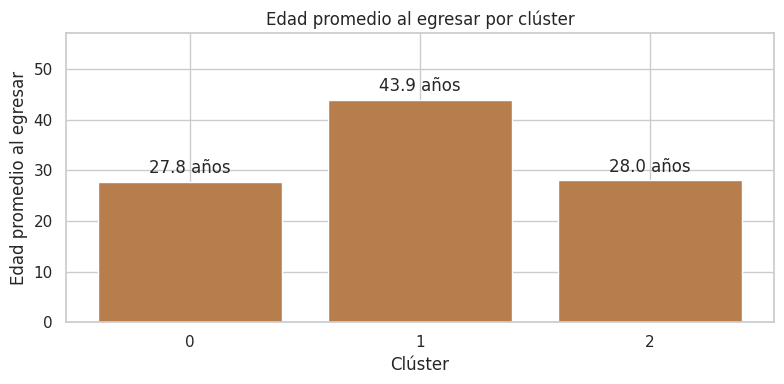

In [170]:
# Tres visualizaciones para leer el tamaño y las diferencias entre grupos.
orden_cl = perfiles_km.index

plt.figure(figsize=(8, 4))
barras = plt.bar(orden_cl.astype(str), perfiles_km['Porcentaje'], color='#4682b4')
plt.bar_label(barras, fmt='%.1f%%', padding=3)
plt.ylim(0, 70)
plt.xlabel('Clúster')
plt.ylabel('Porcentaje de personas')
plt.title('Tamaño relativo de los clústeres (2021)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
barras = plt.bar(orden_cl.astype(str), perfiles_km['Salario_mediano'], color='#669c86')
plt.bar_label(barras, labels=[f'${v:,.0f}' for v in perfiles_km['Salario_mediano']], padding=3)
plt.ylim(0, perfiles_km['Salario_mediano'].max()*1.25)
plt.xlabel('Clúster')
plt.ylabel('Salario mediano en pesos de 2021')
plt.title('Comparación de salarios medianos por clúster')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
barras = plt.bar(orden_cl.astype(str), perfiles_km['Edad_promedio'], color='#b77d4c')
plt.bar_label(barras, fmt='%.1f años', padding=3)
plt.ylim(0, perfiles_km['Edad_promedio'].max()*1.3)
plt.xlabel('Clúster')
plt.ylabel('Edad promedio al egresar')
plt.title('Edad promedio al egresar por clúster')
plt.tight_layout()
plt.show()

#### Interpretación de los perfiles hallados (K=3)

Con esta preparación y la ejecución reproducible del modelo se identificaron los siguientes perfiles:

- **Clúster 0 (aprox. 52%):** graduados que egresaron relativamente jóvenes (**27,8 años** en promedio) y presentan una remuneración media más elevada (aprox. $180.34). La rama más frecuente es Ciencias Sociales, entre otras.

- **Clúster 1 (aprox. 20,7%):** graduados que egresaron a edades mayores (44 años en promedio), con remuneraciones medias también elevadas (aprox. $179.076).   Tiene una mayor proporción de títulos de posgrado (21,3%) que los otros grupos y un mayor porcentaje de mujeres (61.6%).

- **Clúster 2 (aprox. 27,4%):** graduados que egresaron jóvenes (28 años en promedio), con remuneración media más baja (aprox. $55.548). Dentro de este clúster predomina la presencia de mujeres (78,7%), aunque esto no demuestra que el género sea la causa de los salarios observados.

Estas etiquetas describen tendencias **dentro de los grupos**, no perfiles cerrados. Los salarios promedio pueden verse afectados por valores extremos: por eso también mostramos la **mediana**, que es más robusta. Las proporciones por rama se deben leer como porcentajes dentro de cada grupo, no como probabilidades de que una rama genere un salario determinado.

### Paso 6. Visualización en dos dimensiones mediante PCA

K-Means agrupa observaciones en un espacio de varias características. UtilizamosAnálisis de Componentes Principales (PCA) únicamente para visualizar esos grupos en dos dimensiones.

Mostramos qué porcentaje de variación representan ambos ejes y las variables que más contribuyen a ellos (sus cargas o loadings). Dibujamos una muestra reproducible de hasta 12.000 personas para evitar que cientos de miles de puntos hagan ilegible la figura.

Variación explicada por PC1: 24.34%
Variación explicada por PC2: 18.86%
Variación total representada en 2D: 43.20%
Variables con mayor carga absoluta en PC1:


,PC1
log_salario,0.722
edad_egreso,0.673
genero_mujer,-0.072
genero_varon,0.072
tipo_titulo_Posgrado,0.070
region_CABA,0.049


Variables con mayor carga absoluta en PC2:


,PC2
edad_egreso,0.721
log_salario,-0.640
genero_varon,-0.119
genero_mujer,0.119
region_CABA,-0.106
rama_Ciencias Humanas,0.100


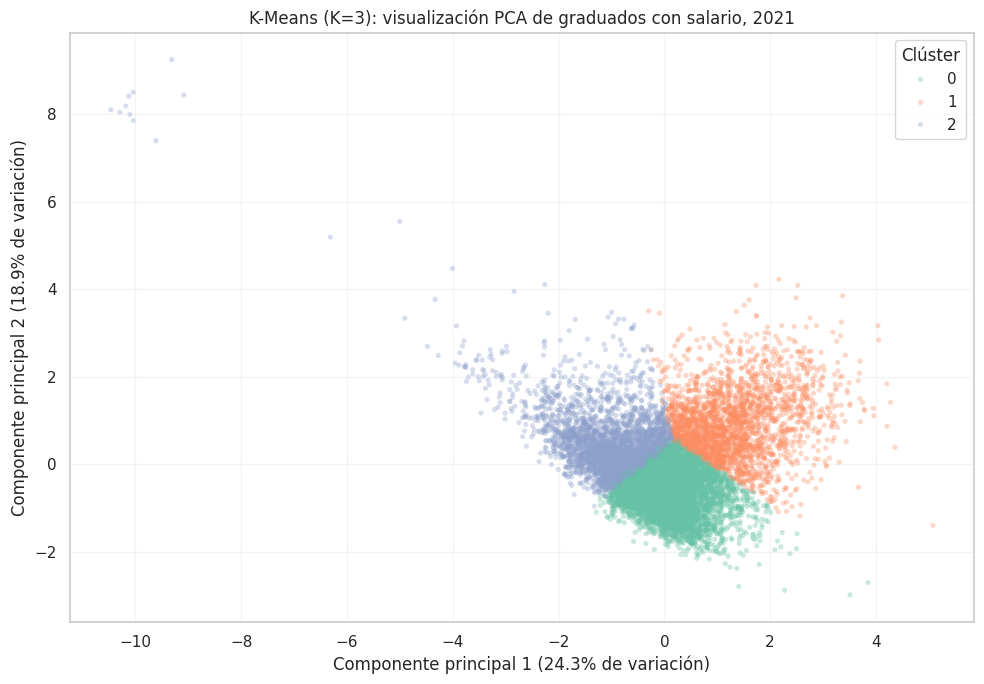

In [171]:
pca = PCA(n_components=2, random_state=42)
X_km_pca = pca.fit_transform(X_km_scaled)

varianza_km = pca.explained_variance_ratio_ * 100
print(f'Variación explicada por PC1: {varianza_km[0]:.2f}%')
print(f'Variación explicada por PC2: {varianza_km[1]:.2f}%')
print(f'Variación total representada en 2D: {varianza_km.sum():.2f}%')

cargas_km = pd.DataFrame(
    pca.components_.T,
    index=columnas_modelo_km,
    columns=['PC1', 'PC2']
)
for pc in ['PC1', 'PC2']:
    print(f'Variables con mayor carga absoluta en {pc}:')
    display(cargas_km.loc[cargas_km[pc].abs().nlargest(6).index, [pc]].round(3))

# Mostrar solo una muestra, sin alterar los clústeres del modelo final.
rng_pca = np.random.default_rng(42)
indices_pca = rng_pca.choice(len(df_kmeans), size=min(12000, len(df_kmeans)), replace=False)
df_grafico = pd.DataFrame({
    'Componente 1': X_km_pca[indices_pca, 0],
    'Componente 2': X_km_pca[indices_pca, 1],
    'Clúster': df_kmeans['cluster'].to_numpy()[indices_pca].astype(str)
})

plt.figure(figsize=(10, 7))
sns.scatterplot(data=df_grafico, x='Componente 1', y='Componente 2',
                hue='Clúster', hue_order=['0','1','2'],
                palette='Set2', alpha=0.35, s=14, linewidth=0)
plt.title('K-Means (K=3): visualización PCA de graduados con salario, 2021')
plt.xlabel(f'Componente principal 1 ({varianza_km[0]:.1f}% de variación)')
plt.ylabel(f'Componente principal 2 ({varianza_km[1]:.1f}% de variación)')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

#### Interpretación de PCA y limitaciones

Los dos componentes representan aproximadamente **43,2% de la variación total** (24,3% el primero y 18,9% el segundo). Las cargas muestran que **PC1** está asociado principalmente a salario logarítmico y edad al egresar, ambos con signo positivo. En **PC2**, la edad tiene signo positivo y el salario logarítmico signo negativo. Los signos de los componentes podrían invertirse sin cambiar su significado matemático.

Al proyectar los datos en dos dimensiones es posible observar zonas de concentración de cada clúster, pero también **solapamiento**. Esto es compatible con los coeficientes de silueta relativamente bajos.

### Conclusión de la técnica K-Means

K-Means permitió describir tres perfiles exploratorios que se diferencian principalmente por edad de egreso y nivel salarial, además de presentar composiciones distintas según rama, título, género y región.

La elección de K=3 fue por su utilidad descriptiva y no porque representen divisiones naturales perfectamente separadas.

El estudio se limita a salarios registrados positivos de 2021, expresados en pesos nominales de ese año; no mide desempleo ni evolución salarial entre años. Como en todo agrupamiento, los resultados dependen de las variables elegidas, su transformación, ponderación y codificación. Los patrones encontrados son asociaciones descriptivas, no relaciones causales.


## 6. Conclusiones generales del trabajo práctico

El objetivo del trabajo fue analizar las características de los graduados universitarios y su relación con la **presencia de remuneraciones registradas** y con los **niveles salariales**, utilizando datos del Sistema Araucano. Para ello se realizó una inspección inicial del conjunto de datos, una etapa de limpieza y transformación, análisis exploratorios y la aplicación de dos técnicas de explotación de la información: **ID3 y K-Means**.

**Análisis exploratorio.** La base original contiene **820.335 registros**, correspondientes a observaciones de graduados en distintos años. Al centrarnos en 2021 y en edades de egreso entre 18 y 85 años, obtuvimos **273.424 personas** para explorar la edad; su mediana de egreso fue de **28 años**. Para analizar remuneraciones se conservaron **162.897 casos con salario positivo registrado**. Sus importes muestran una distribución asimétrica: el promedio fue de aproximadamente **$145.899** y la mediana de **$119.289** (pesos nominales de 2021). Estas observaciones justificaron tanto la agrupación de edades en intervalos como la transformación logarítmica del salario utilizada en K-Means.

**Diferencias salariales por género.** En los registros de 2021 con salario positivo, el salario promedio de las mujeres fue de aproximadamente **$130.711**, frente a **$167.933** para los varones, con una diferencia descriptiva cercana al **22,2%** respecto del promedio de los varones. También hubo una diferencia en las medianas. No obstante, el análisis no controla por rama, región, especialidad, características laborales u otros factores, por lo que **no permite atribuir causalmente esa diferencia al género ni afirmar que se pague distinto por un mismo trabajo**.

**Resultados de ID3.** El árbol seleccionó el **tramo de edad** como primera variable por su ganancia de información, seguido muy de cerca por la **región**. Su exactitud fue del **61,40%**, frente al **58,49%** de una predicción que siempre eligiera la clase mayoritaria. Además, identificó mejor los registros con salario que aquellos sin salario. Esto muestra que el árbol permite **interpretar reglas y asociaciones** entre variables, pero tiene un rendimiento predictivo moderado y no es adecuado para determinar con certeza la situación laboral individual.

**Resultados de K-Means.** Con las personas que tenían salario positivo en 2021 se exploraron tres perfiles. El **clúster 0** (aproximadamente **52%**) reúne graduados de menor edad de egreso y remuneraciones relativamente altas; el **clúster 1** (**20,7%**) incluye graduados de mayor edad de egreso con salarios medios también elevados; y el **clúster 2** (**27,4%**) presenta edades de egreso relativamente bajas y remuneraciones menores. La comparación de K mostró que **K=2 tenía mejor coeficiente de silueta que K=3**, pero se conservó K=3 por su utilidad descriptiva. La superposición observada mediante PCA y los coeficientes de silueta bajos indican que estos grupos **no están completamente separados**.

**Integración de las técnicas y limitaciones.** ID3 respondió a la pregunta de qué características permiten clasificar la **presencia de salario registrado**, mientras que K-Means permitió explorar **diferentes perfiles entre quienes sí registran un salario positivo**. Por eso, las técnicas son complementarias, aunque sus resultados no son directamente comparables como medidas de desempeño. Debe considerarse que **un salario ausente en la base no equivale necesariamente a desempleo**, que las remuneraciones analizadas corresponden a **pesos nominales de 2021** y que tanto las reglas del árbol como los agrupamientos dependen de las variables disponibles y las decisiones de preprocesamiento. Ninguno de estos análisis demuestra relaciones causales.

**Conclusión final.** El trabajo permitió transformar una base amplia de datos administrativos en información interpretable sobre las características y remuneraciones de los graduados. Se identificaron diferencias relevantes según la edad de egreso, la región, el género y los perfiles académicos, aunque las variables estudiadas explican solo una parte del fenómeno laboral. Como posible continuidad, sería interesante comparar los salarios **dentro de las mismas ramas de estudio y regiones**, incorporar más variables laborales y evaluar modelos alternativos. De esta manera, los resultados actuales constituyen un **punto de partida exploratorio**, y no una explicación definitiva de las diferencias observadas.